<a href="https://colab.research.google.com/github/Pbartuiyot/Advance-Machine-Learning/blob/main/airbnb_boston_sentimental_analysis_customer_reviews.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Airbnb Boston Sentimental Analysis -Customer Reviews**

Airbnb hosts in Boston struggle to attract guests due to poor pricing, limited visibility, and listings that don't highlight local attractions or unique features. Without proper data analytics, many set prices that are either too high, driving away bookings, or too low, hurting profitability. This limits Airbnb’s growth and undermines local economic benefits while missing opportunities to promote Boston cultural heritage.Unlike hotels that rely on brand recognition, Airbnb guests depend on user reviews and listing details to gauge value, often willing to pay more for well-rated properties. However, hosts don’t have clear guidance on which features, like location, amenities, or host responsiveness, affect guest satisfaction and pricing.


By analyzing reviews, proximity to attractions, seasonal demand, and host service quality, we will extract key insights. Natural language processing (NLP) will help identify what guests value, their expectations, and improvement areas. This will enable hosts to set competitive prices that balance occupancy and profitability. Improve listing quality based on guest preferences. Increase visibility by showcasing unique features and local attractions.

In [105]:
import numpy as np
import pandas as pd
import seaborn as sns
import re
import nltk
import matplotlib.pyplot as plt
from collections import Counter
import warnings
warnings.filterwarnings('ignore')
nltk.download('stopwords')
nltk.download('punkt')
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem.porter import PorterStemmer
from nltk.sentiment.vader import SentimentIntensityAnalyzer
nltk.download('averaged_perceptron_tagger')
nltk.download('maxent_ne_chunker')
nltk.download('words')
nltk.download('vader_lexicon')
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package maxent_ne_chunker to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package maxent_ne_chunker is already up-to-date!
[nltk_data] Downloading package words to /root/nltk_data...
[nltk_data]   Package words is already up-to-date!
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


# Reading and understanding the Data

In [106]:
listing = pd.read_csv('/content/boston_airbnb_listing.csv')
reviews = pd.read_csv('/content/boston_airbnb_customer_reviews.csv')

In [107]:
listing.head()

,id,listing_url,scrape_id,last_scraped,name,summary,space,description,experiences_offered,neighborhood_overview,...,review_scores_value,requires_license,license,jurisdiction_names,instant_bookable,cancellation_policy,require_guest_profile_picture,require_guest_phone_verification,calculated_host_listings_count,reviews_per_month
0,12147973,https://www.airbnb.com/rooms/12147973,2.016090e+13,07/09/2016,Sunny Bungalow in the City,"Cozy, sunny, family home. Master bedroom high...",The house has an open and cozy feel at the sam...,"Cozy, sunny, family home. Master bedroom high...",none,"Roslindale is quiet, convenient and friendly. ...",...,NaN,f,NaN,NaN,f,moderate,f,f,1,NaN
1,3075044,https://www.airbnb.com/rooms/3075044,2.016090e+13,07/09/2016,Charming room in pet friendly apt,Charming and quiet room in a second floor 1910...,Small but cozy and quite room with a full size...,Charming and quiet room in a second floor 1910...,none,"The room is in Roslindale, a diverse and prima...",...,9.0,f,NaN,NaN,t,moderate,f,f,1,1.30
2,6976,https://www.airbnb.com/rooms/6976,2.016090e+13,07/09/2016,Mexican Folk Art Haven in Boston,"Come stay with a friendly, middle-aged guy in ...","Come stay with a friendly, middle-aged guy in ...","Come stay with a friendly, middle-aged guy in ...",none,The LOCATION: Roslindale is a safe and diverse...,...,10.0,f,NaN,NaN,f,moderate,t,f,1,0.47
3,1436513,https://www.airbnb.com/rooms/1436513,2.016090e+13,07/09/2016,Spacious Sunny Bedroom Suite in Historic Home,Come experience the comforts of home away from...,Most places you find in Boston are small howev...,Come experience the comforts of home away from...,none,Roslindale is a lovely little neighborhood loc...,...,10.0,f,NaN,NaN,f,moderate,f,f,1,1.00
4,7651065,https://www.airbnb.com/rooms/7651065,2.016090e+13,07/09/2016,Come Home to Boston,"My comfy, clean and relaxing home is one block...","Clean, attractive, private room, one block fro...","My comfy, clean and relaxing home is one block...",none,"I love the proximity to downtown, the neighbor...",...,10.0,f,NaN,NaN,f,flexible,f,f,1,2.25


Customer Reviews Heads

In [108]:
reviews.head()

,listing_id,id,date,reviewer_id,reviewer_name,comments
0,1178162,15846810,16/07/2014,17826223,Raija,OK stay. Perhaps best for those on the young/...
1,1178162,15895093,17/07/2014,18020631,Lucas,Izzy was very helpful with directions and he w...
2,1178162,15982012,19/07/2014,7543714,Anne-Marie,This was ok it was easy with clear information...
3,1178162,16035159,20/07/2014,17287987,Shu-Ping,Izzy was out of the town when I stayed there. ...
4,1178162,16221436,23/07/2014,2420725,Jessica,"Unfortunately, we can't agree with the many po..."


In [109]:
listing.describe()

,id,scrape_id,host_id,host_listings_count,host_total_listings_count,neighbourhood_group_cleansed,latitude,longitude,accommodates,bathrooms,...,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,jurisdiction_names,calculated_host_listings_count,reviews_per_month
count,3.585000e+03,3.585000e+03,3.585000e+03,3585.000000,3585.000000,0.0,3585.000000,3585.000000,3585.000000,3571.000000,...,2762.000000,2767.000000,2765.000000,2767.000000,2763.000000,2764.000000,0.0,0.0,3585.000000,2829.000000
mean,8.440875e+06,2.016090e+13,2.492311e+07,58.902371,58.902371,NaN,42.340032,-71.084818,3.041283,1.221647,...,9.431571,9.258041,9.646293,9.646549,9.414043,9.168234,NaN,NaN,12.733891,1.970908
std,4.500787e+06,0.000000e+00,2.292781e+07,171.119663,171.119663,NaN,0.024403,0.031565,1.778929,0.501487,...,0.931863,1.168977,0.762753,0.735507,0.903436,1.011116,NaN,NaN,29.415076,2.120561
min,3.353000e+03,2.016090e+13,4.240000e+03,0.000000,0.000000,NaN,42.235942,-71.171789,1.000000,0.000000,...,2.000000,2.000000,2.000000,4.000000,2.000000,2.000000,NaN,NaN,1.000000,0.010000
25%,4.679319e+06,2.016090e+13,6.103425e+06,1.000000,1.000000,NaN,42.329995,-71.105083,2.000000,1.000000,...,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,NaN,NaN,1.000000,0.480000
50%,8.577620e+06,2.016090e+13,1.928100e+07,2.000000,2.000000,NaN,42.345201,-71.078429,2.000000,1.000000,...,10.000000,10.000000,10.000000,10.000000,10.000000,9.000000,NaN,NaN,2.000000,1.170000
75%,1.278953e+07,2.016090e+13,3.622147e+07,7.000000,7.000000,NaN,42.354685,-71.062155,4.000000,1.000000,...,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,NaN,NaN,6.000000,2.720000
max,1.493346e+07,2.016090e+13,9.385411e+07,749.000000,749.000000,NaN,42.389982,-71.000100,16.000000,6.000000,...,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,NaN,NaN,136.000000,19.150000


Exploration of the Individual Datasets

In [110]:
listing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3585 entries, 0 to 3584
Data columns (total 95 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   id                                3585 non-null   int64  
 1   listing_url                       3585 non-null   object 
 2   scrape_id                         3585 non-null   float64
 3   last_scraped                      3585 non-null   object 
 4   name                              3585 non-null   object 
 5   summary                           3442 non-null   object 
 6   space                             2528 non-null   object 
 7   description                       3585 non-null   object 
 8   experiences_offered               3585 non-null   object 
 9   neighborhood_overview             2170 non-null   object 
 10  notes                             1610 non-null   object 
 11  transit                           2295 non-null   object 
 12  access

In [111]:
reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63415 entries, 0 to 63414
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   listing_id     63415 non-null  int64 
 1   id             63415 non-null  int64 
 2   date           63415 non-null  object
 3   reviewer_id    63415 non-null  int64 
 4   reviewer_name  63415 non-null  object
 5   comments       63366 non-null  object
dtypes: int64(3), object(3)
memory usage: 2.9+ MB


In [112]:
reviews.describe()

,listing_id,id,reviewer_id
count,6.341500e+04,6.341500e+04,6.341500e+04
mean,4.754891e+06,5.238851e+07,2.791957e+07
std,3.810116e+06,2.802650e+07,2.235520e+07
min,5.506000e+03,1.021000e+03,1.430000e+02
25%,1.373520e+06,2.977688e+07,8.876600e+06
50%,4.054079e+06,5.213034e+07,2.286488e+07
75%,7.434871e+06,7.670071e+07,4.197486e+07
max,1.484378e+07,9.999045e+07,9.335034e+07


In [113]:
listing['city'].value_counts()

,count
city,
Boston,3381
Roxbury Crossing,24
Somerville,19
Jamaica Plain,18
Brookline,18
Cambridge,16
Brighton,15
Dorchester,15
Charlestown,15


In [114]:
listing['cancellation_policy'].value_counts()

,count
cancellation_policy,
strict,1582
flexible,999
moderate,919
super_strict_30,85


In [115]:
listing['host_response_time'].value_counts()

,count
host_response_time,
within an hour,1384
within a few hours,1218
within a day,469
a few days or more,43


In [116]:
listing['street'].value_counts()

,count
street,
"Boylston Street, Boston, MA 02215, United States",64
"Beacon Street, Boston, MA 02116, United States",50
"Garrison Street, Boston, MA 02116, United States",44
"Brookline Avenue, Boston, MA 02215, United States",41
"Columbus Avenue, Boston, MA 02116, United States",31
...,...
"Metropolitan Ave, Boston, MA 02131, United States",1
"Chisholm Lane, Boston, MA 02131, United States",1
"Westbourne Terrace, Brookline, MA 02446, United States",1


In [117]:
listing['smart_location'].value_counts()

,count
smart_location,
"Boston, MA",3381
"Roxbury Crossing, MA",24
"Somerville, MA",19
"Brookline, MA",18
"Jamaica Plain, MA",18
"Cambridge, MA",16
"Charlestown, MA",15
"Brighton, MA",15
"Dorchester, MA",15


In [118]:
listing['is_location_exact'].value_counts()

,count
is_location_exact,
t,3080
f,505


In [119]:
listing.describe(include='object')

,listing_url,last_scraped,name,summary,space,description,experiences_offered,neighborhood_overview,notes,transit,...,extra_people,calendar_updated,calendar_last_scraped,first_review,last_review,requires_license,instant_bookable,cancellation_policy,require_guest_profile_picture,require_guest_phone_verification
count,3585,3585,3585,3442,2528,3585,3585,2170,1610,2295,...,3585,3585,3585,2829,2829,3585,3585,3585,3585,3585
unique,3585,1,3504,3113,2268,3423,1,1728,1266,1852,...,51,38,1,975,404,1,2,4,2,2
top,https://www.airbnb.com/rooms/14504422,07/09/2016,Lux 2BR by Fenway w/WiFi,"The unit is stylishly designed for comfort, va...",The studio's kitchenette comes equipped with a...,"The unit is stylishly designed for comfort, va...",none,Conveniently bordering the neighborhoods of th...,Although we do not allow pets in our apartment...,"These newly constructed, luxury apartments epi...",...,$0.00,today,06/09/2016,05/04/2016,05/09/2016,f,f,strict,f,f
freq,1,3585,8,21,17,7,3585,21,44,26,...,2211,833,3585,23,118,3585,2991,1582,3518,3348


Data Cleaning

In [120]:
listing.duplicated().sum()

np.int64(0)

In [121]:
print(listing.isnull().sum())

id                                    0
listing_url                           0
scrape_id                             0
last_scraped                          0
name                                  0
                                   ... 
cancellation_policy                   0
require_guest_profile_picture         0
require_guest_phone_verification      0
calculated_host_listings_count        0
reviews_per_month                   756
Length: 95, dtype: int64


In [122]:
listing.drop_duplicates(inplace=True)

In [123]:
reviews.duplicated().sum()

np.int64(0)

# **Merging the AirBnB Listing and Customer Review Datasets**

To understand the overall sentiment for each listing, I first conducted the merging of the two datasets to come up with one dataset that will allow me perform the classification. As this will give the view of relationship/ association between the customer reviews and their listings. This will also mean I can trace the data back to their group.

In [142]:
merged_data = pd.merge(listing, reviews, left_on='id', right_on='listing_id', how='inner')

print("Customer Reviews by Listing:")
display(merged_data.head())

Customer Reviews by Listing:


,id_x,listing_url,scrape_id,last_scraped,name,summary,space,description,experiences_offered,neighborhood_overview,...,listing_id,id_y,date,reviewer_id,reviewer_name,comments,negativity,neutrality,positivity,compound
0,3075044,https://www.airbnb.com/rooms/3075044,2.016090e+13,07/09/2016,Charming room in pet friendly apt,Charming and quiet room in a second floor 1910...,Small but cozy and quite room with a full size...,Charming and quiet room in a second floor 1910...,none,"The room is in Roslindale, a diverse and prima...",...,3075044,13631717,01/06/2014,9645972,Dmitrii,Andrea is a great host. Neighborhood is wonder...,0.0,0.658,0.342,0.9438
1,3075044,https://www.airbnb.com/rooms/3075044,2.016090e+13,07/09/2016,Charming room in pet friendly apt,Charming and quiet room in a second floor 1910...,Small but cozy and quite room with a full size...,Charming and quiet room in a second floor 1910...,none,"The room is in Roslindale, a diverse and prima...",...,3075044,13866662,06/06/2014,12020681,Paola,We had a great time at Andrea's place. He is v...,0.0,0.478,0.522,0.9915
2,3075044,https://www.airbnb.com/rooms/3075044,2.016090e+13,07/09/2016,Charming room in pet friendly apt,Charming and quiet room in a second floor 1910...,Small but cozy and quite room with a full size...,Charming and quiet room in a second floor 1910...,none,"The room is in Roslindale, a diverse and prima...",...,3075044,14990373,30/06/2014,8165047,Jaydee,Adrea was very welcoming and flexible to our n...,0.0,0.611,0.389,0.9604
3,3075044,https://www.airbnb.com/rooms/3075044,2.016090e+13,07/09/2016,Charming room in pet friendly apt,Charming and quiet room in a second floor 1910...,Small but cozy and quite room with a full size...,Charming and quiet room in a second floor 1910...,none,"The room is in Roslindale, a diverse and prima...",...,3075044,19807601,18/09/2014,21319433,Anthony,Andrea made us feel welcome because he made th...,0.0,0.800,0.200,0.8588
4,3075044,https://www.airbnb.com/rooms/3075044,2.016090e+13,07/09/2016,Charming room in pet friendly apt,Charming and quiet room in a second floor 1910...,Small but cozy and quite room with a full size...,Charming and quiet room in a second floor 1910...,none,"The room is in Roslindale, a diverse and prima...",...,3075044,20322887,27/09/2014,21706950,Xinny,Me and my friend were so happy about Andrea's ...,0.0,0.614,0.386,0.9644


In [143]:
reviews_per_listing = merged_data.groupby('listing_id').size().reset_index(name='number_of_reviews')

print("Number of reviews per listing ID:")
display(reviews_per_listing.head())

Number of reviews per listing ID:


,listing_id,number_of_reviews
0,5506,36
1,6695,47
2,6976,41
3,8792,18
4,9273,13


**Peforming the Sentimental analysis **

Using VADER I performed the sentimental analysis to come up with the scores for each customer review. This allows me to calculate scores for negativity, neutrality, positivity, and a combined compound score, which are then added as new columns to the dataset. This allows to quantify the sentiment expressed in each review.


In [126]:
analyzer = SentimentIntensityAnalyzer()

def get_sentiment_scores(text):
    if isinstance(text, str):
        return analyzer.polarity_scores(text)
    else:
        return {'neg': 0, 'neu': 0, 'pos': 0, 'compound': 0}

reviews[['negativity', 'neutrality', 'positivity', 'compound']] = reviews['comments'].apply(lambda x: pd.Series(get_sentiment_scores(x)))

scored_reviews = reviews.copy()

print("Reviews with sentiment scores:")
display(scored_reviews.head())

Reviews with sentiment scores:


,listing_id,id,date,reviewer_id,reviewer_name,comments,negativity,neutrality,positivity,compound
0,1178162,15846810,16/07/2014,17826223,Raija,OK stay. Perhaps best for those on the young/...,0.035,0.885,0.080,0.7141
1,1178162,15895093,17/07/2014,18020631,Lucas,Izzy was very helpful with directions and he w...,0.032,0.772,0.195,0.9713
2,1178162,15982012,19/07/2014,7543714,Anne-Marie,This was ok it was easy with clear information...,0.063,0.705,0.233,0.7880
3,1178162,16035159,20/07/2014,17287987,Shu-Ping,Izzy was out of the town when I stayed there. ...,0.000,0.835,0.165,0.7579
4,1178162,16221436,23/07/2014,2420725,Jessica,"Unfortunately, we can't agree with the many po...",0.034,0.666,0.299,0.9934


In [127]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Select numerical columns for PCA (sentiment scores)
pca_data = scored_reviews[['negativity', 'neutrality', 'positivity', 'compound']].copy()

# Standardize the data
scaler = StandardScaler()
scaled_pca_data = scaler.fit_transform(pca_data)

# Perform PCA
pca = PCA(n_components=2) # You can adjust the number of components
principal_components = pca.fit_transform(scaled_pca_data)

# Create a new DataFrame with the principal components
pca_df = pd.DataFrame(data = principal_components, columns = ['principal_component_1', 'principal_component_2'])

# Display the first few rows of the PCA dataframe
print("Principal Components of Sentiment Scores:")
display(pca_df.head())

Principal Components of Sentiment Scores:


,principal_component_1,principal_component_2
0,-1.807066,-0.398518
1,-0.530622,-0.216694
2,-0.652501,0.937718
3,-0.911155,-0.904273
4,0.300890,0.306501


In [128]:
# Get the topic distribution for each review
topic_distribution = lda.transform(tfidf_matrix)

# Assign the dominant topic to each review
# Find the topic index with the highest probability for each review
dominant_topic = topic_distribution.argmax(axis=1)

# Add the dominant topic as a new column in the scored_reviews dataframe
scored_reviews['dominant_topic'] = dominant_topic

# Calculate the average sentiment scores for each topic
sentiment_per_topic = scored_reviews.groupby('dominant_topic')[['negativity', 'neutrality', 'positivity', 'compound']].mean()

print("Average sentiment scores per topic:")
display(sentiment_per_topic)

Average sentiment scores per topic:


,negativity,neutrality,positivity,compound
dominant_topic,,,,
0,0.038013,0.909872,0.031059,-0.048286
1,0.006303,0.609554,0.384143,0.889515
2,0.026808,0.754404,0.218784,0.634125
3,0.012053,0.713829,0.274115,0.892226
4,0.022446,0.743458,0.234096,0.860075


Model

In [129]:
# Function to display the top words for each topic
def display_topics(model, feature_names, no_top_words):
    for topic_idx, topic in enumerate(model.components_):
        print("Topic %d:" % (topic_idx))
        print(" ".join([feature_names[i]
                        for i in topic.argsort()[:-no_top_words - 1:-1]]))

# Get the feature names (words) from the TF-IDF vectorizer
tfidf_feature_names = tfidf_vectorizer.get_feature_names_out()

# Display the top 10 words for each topic
no_top_words = 10
display_topics(lda, tfidf_feature_names, no_top_words)

Topic 0:
la et le tr en est nou muy und dan
Topic 1:
great stay place locat host apart nice clean boston recommend
Topic 2:
arriv reserv day post cancel autom host great stay good
Topic 3:
great walk boston stay locat apart place close restaur clean
Topic 4:
room stay hous great apart nice place clean boston comfort


In [130]:
# Save the scored_reviews dataframe to a CSV file
scored_reviews.to_csv('scored_reviews.csv', index=False)

print("scored_reviews.csv has been saved.")

scored_reviews.csv has been saved.


In [131]:
nltk.download('punkt_tab')

stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def preprocess_text(text):
    if isinstance(text, str):
        text = text.lower()
        text = re.sub(r'[^a-zA-Z\s]', '', text)  # Remove non-alphabetic characters
        tokens = word_tokenize(text)
        stemmed_tokens = [stemmer.stem(word) for word in tokens if word not in stop_words]
        return ' '.join(stemmed_tokens)
    else:
        return '' # Return an empty string for non-string values

scored_reviews['cleaned_comments'] = scored_reviews['comments'].apply(preprocess_text)

# Display the first few rows with the cleaned comments
print("Reviews with cleaned comments:")
display(scored_reviews[['comments', 'cleaned_comments']].head())

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Reviews with cleaned comments:


,comments,cleaned_comments
0,OK stay. Perhaps best for those on the young/...,ok stay perhap best youngadventur side spectru...
1,Izzy was very helpful with directions and he w...,izzi help direct easi get touch question great...
2,This was ok it was easy with clear information...,ok easi clear inform get hous safe host wasnt ...
3,Izzy was out of the town when I stayed there. ...,izzi town stay locat close airport neighborhoo...
4,"Unfortunately, we can't agree with the many po...",unfortun cant agre mani posit review hous easi...


In [132]:
# Merge the average sentiment scores and dominant topic back into the listing dataframe
# First, calculate the average sentiment scores and dominant topic per listing
average_sentiment_per_listing = scored_reviews.groupby('listing_id')[['negativity', 'neutrality', 'positivity', 'compound']].mean().reset_index()
dominant_topic_per_listing = scored_reviews.groupby('listing_id')['dominant_topic'].agg(lambda x: x.mode()[0]).reset_index()

# Merge these back into the listing dataframe
listing_with_sentiment = pd.merge(listing, average_sentiment_per_listing, left_on='id', right_on='listing_id', how='left')
listing_with_sentiment_and_topic = pd.merge(listing_with_sentiment, dominant_topic_per_listing, left_on='id', right_on='listing_id', how='left')

# Drop the duplicate listing_id columns
listing_with_sentiment_and_topic.drop(['listing_id_x', 'listing_id_y'], axis=1, inplace=True)

print("Listing dataframe with sentiment scores and dominant topic:")
display(listing_with_sentiment_and_topic.head())

Listing dataframe with sentiment scores and dominant topic:


,id,listing_url,scrape_id,last_scraped,name,summary,space,description,experiences_offered,neighborhood_overview,...,cancellation_policy,require_guest_profile_picture,require_guest_phone_verification,calculated_host_listings_count,reviews_per_month,negativity,neutrality,positivity,compound,dominant_topic
0,12147973,https://www.airbnb.com/rooms/12147973,2.016090e+13,07/09/2016,Sunny Bungalow in the City,"Cozy, sunny, family home. Master bedroom high...",The house has an open and cozy feel at the sam...,"Cozy, sunny, family home. Master bedroom high...",none,"Roslindale is quiet, convenient and friendly. ...",...,moderate,f,f,1,NaN,NaN,NaN,NaN,NaN,NaN
1,3075044,https://www.airbnb.com/rooms/3075044,2.016090e+13,07/09/2016,Charming room in pet friendly apt,Charming and quiet room in a second floor 1910...,Small but cozy and quite room with a full size...,Charming and quiet room in a second floor 1910...,none,"The room is in Roslindale, a diverse and prima...",...,moderate,f,f,1,1.30,0.014000,0.664056,0.321944,0.837644,1.0
2,6976,https://www.airbnb.com/rooms/6976,2.016090e+13,07/09/2016,Mexican Folk Art Haven in Boston,"Come stay with a friendly, middle-aged guy in ...","Come stay with a friendly, middle-aged guy in ...","Come stay with a friendly, middle-aged guy in ...",none,The LOCATION: Roslindale is a safe and diverse...,...,moderate,t,f,1,0.47,0.010854,0.724488,0.264659,0.905349,4.0
3,1436513,https://www.airbnb.com/rooms/1436513,2.016090e+13,07/09/2016,Spacious Sunny Bedroom Suite in Historic Home,Come experience the comforts of home away from...,Most places you find in Boston are small howev...,Come experience the comforts of home away from...,none,Roslindale is a lovely little neighborhood loc...,...,moderate,f,f,1,1.00,0.000000,0.516000,0.484000,0.950600,1.0
4,7651065,https://www.airbnb.com/rooms/7651065,2.016090e+13,07/09/2016,Come Home to Boston,"My comfy, clean and relaxing home is one block...","Clean, attractive, private room, one block fro...","My comfy, clean and relaxing home is one block...",none,"I love the proximity to downtown, the neighbor...",...,flexible,f,f,1,2.25,0.017034,0.709069,0.273897,0.780959,1.0


In [133]:
# Convert 'price' column to numeric
# Remove '$' and ',' and convert to float
listing_with_sentiment_and_topic['price'] = listing_with_sentiment_and_topic['price'].replace({'\$': '', ',': ''}, regex=True).astype(float)

# Select the relevant columns for correlation analysis
correlation_columns = [
    'price',
    'review_scores_rating',
    'review_scores_accuracy',
    'review_scores_cleanliness',
    'review_scores_checkin',
    'review_scores_communication',
    'review_scores_location',
    'review_scores_value',
    'negativity',
    'neutrality',
    'positivity',
    'compound',
    'dominant_topic'
]

# Calculate the correlation matrix
correlation_matrix = listing_with_sentiment_and_topic[correlation_columns].corr()

# Display the correlation matrix
print("Correlation Matrix (Sentiment, Topics, Price, and Review Scores):")
display(correlation_matrix)

Correlation Matrix (Sentiment, Topics, Price, and Review Scores):


,price,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,negativity,neutrality,positivity,compound,dominant_topic
price,1.000000,0.105651,0.041204,0.146548,-0.003851,0.003614,0.193928,0.011834,-0.037782,-0.015604,0.034321,0.082868,-0.029725
review_scores_rating,0.105651,1.000000,0.705104,0.754327,0.584034,0.600599,0.458901,0.786320,-0.444781,-0.239837,0.351519,0.528359,-0.134828
review_scores_accuracy,0.041204,0.705104,1.000000,0.643754,0.468127,0.492731,0.325403,0.665131,-0.309259,-0.216819,0.290966,0.425876,-0.129020
review_scores_cleanliness,0.146548,0.754327,0.643754,1.000000,0.461132,0.428085,0.353038,0.654177,-0.326854,-0.183010,0.266793,0.425803,-0.114164
review_scores_checkin,-0.003851,0.584034,0.468127,0.461132,1.000000,0.672463,0.280325,0.494745,-0.261784,-0.149911,0.216115,0.340711,-0.084602
review_scores_communication,0.003614,0.600599,0.492731,0.428085,0.672463,1.000000,0.286326,0.529203,-0.298047,-0.146064,0.218966,0.372550,-0.085993
review_scores_location,0.193928,0.458901,0.325403,0.353038,0.280325,0.286326,1.000000,0.439770,-0.230354,-0.133193,0.194313,0.295086,-0.102617
review_scores_value,0.011834,0.786320,0.665131,0.654177,0.494745,0.529203,0.439770,1.000000,-0.322381,-0.200240,0.282145,0.432822,-0.118719
negativity,-0.037782,-0.444781,-0.309259,-0.326854,-0.261784,-0.298047,-0.230354,-0.322381,1.000000,-0.025793,-0.220255,-0.380340,0.105520
neutrality,-0.015604,-0.239837,-0.216819,-0.183010,-0.149911,-0.146064,-0.133193,-0.200240,-0.025793,1.000000,-0.948678,-0.511771,0.175853


In [134]:
# Drop rows with missing values in the relevant columns for modeling
model_data = listing_with_sentiment_and_topic.dropna(subset=correlation_columns).copy()

print("Shape of data after dropping rows with missing values:", model_data.shape)
display(model_data.head())

Shape of data after dropping rows with missing values: (2594, 100)


,id,listing_url,scrape_id,last_scraped,name,summary,space,description,experiences_offered,neighborhood_overview,...,cancellation_policy,require_guest_profile_picture,require_guest_phone_verification,calculated_host_listings_count,reviews_per_month,negativity,neutrality,positivity,compound,dominant_topic
1,3075044,https://www.airbnb.com/rooms/3075044,2.016090e+13,07/09/2016,Charming room in pet friendly apt,Charming and quiet room in a second floor 1910...,Small but cozy and quite room with a full size...,Charming and quiet room in a second floor 1910...,none,"The room is in Roslindale, a diverse and prima...",...,moderate,f,f,1,1.30,0.014000,0.664056,0.321944,0.837644,1.0
2,6976,https://www.airbnb.com/rooms/6976,2.016090e+13,07/09/2016,Mexican Folk Art Haven in Boston,"Come stay with a friendly, middle-aged guy in ...","Come stay with a friendly, middle-aged guy in ...","Come stay with a friendly, middle-aged guy in ...",none,The LOCATION: Roslindale is a safe and diverse...,...,moderate,t,f,1,0.47,0.010854,0.724488,0.264659,0.905349,4.0
3,1436513,https://www.airbnb.com/rooms/1436513,2.016090e+13,07/09/2016,Spacious Sunny Bedroom Suite in Historic Home,Come experience the comforts of home away from...,Most places you find in Boston are small howev...,Come experience the comforts of home away from...,none,Roslindale is a lovely little neighborhood loc...,...,moderate,f,f,1,1.00,0.000000,0.516000,0.484000,0.950600,1.0
4,7651065,https://www.airbnb.com/rooms/7651065,2.016090e+13,07/09/2016,Come Home to Boston,"My comfy, clean and relaxing home is one block...","Clean, attractive, private room, one block fro...","My comfy, clean and relaxing home is one block...",none,"I love the proximity to downtown, the neighbor...",...,flexible,f,f,1,2.25,0.017034,0.709069,0.273897,0.780959,1.0
5,12386020,https://www.airbnb.com/rooms/12386020,2.016090e+13,07/09/2016,Private Bedroom + Great Coffee,Super comfy bedroom plus your own bathroom in ...,Our sunny condo is located on the second and t...,Super comfy bedroom plus your own bathroom in ...,none,We love our corner of Roslindale! For quiet wa...,...,flexible,f,f,1,1.70,0.007750,0.756125,0.236125,0.824700,4.0


In [135]:
# Define the target variable (y) and features (X)

# For dynamic pricing, 'price' is a suitable target variable
y = model_data['price']

# Features (X) will be the rest of the relevant columns.
# We'll need to carefully select features, considering categorical and numerical types later.
# For now, let's include the sentiment and topic features along with some other relevant columns.
# We'll refine this feature set in subsequent steps.

# Let's start by including numerical features and the dominant topic for now.
# We'll handle categorical features like 'room_type', 'property_type', etc., later.
X = model_data[[
    'accommodates',
    'bathrooms',
    'bedrooms',
    'beds',
    'guests_included',
    'minimum_nights',
    'maximum_nights',
    'number_of_reviews',
    'review_scores_rating',
    'review_scores_accuracy',
    'review_scores_cleanliness',
    'review_scores_checkin',
    'review_scores_communication',
    'review_scores_location',
    'review_scores_value',
    'negativity',
    'neutrality',
    'positivity',
    'compound',
    'dominant_topic' # Treat dominant_topic as a numerical feature for now, will consider one-hot encoding later if needed
]].copy()

print("Shape of features (X):", X.shape)
print("Shape of target (y):", y.shape)

display(X.head())
display(y.head())

Shape of features (X): (2594, 20)
Shape of target (y): (2594,)


,accommodates,bathrooms,bedrooms,beds,guests_included,minimum_nights,maximum_nights,number_of_reviews,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,negativity,neutrality,positivity,compound,dominant_topic
1,2,1.0,1.0,1.0,0,2,15,36,94.0,10.0,9.0,10.0,10.0,9.0,9.0,0.014000,0.664056,0.321944,0.837644,1.0
2,2,1.0,1.0,1.0,1,3,45,41,98.0,10.0,9.0,10.0,10.0,9.0,10.0,0.010854,0.724488,0.264659,0.905349,4.0
3,4,1.0,1.0,2.0,2,1,1125,1,100.0,10.0,10.0,10.0,10.0,10.0,10.0,0.000000,0.516000,0.484000,0.950600,1.0
4,2,1.5,1.0,2.0,1,2,31,29,99.0,10.0,10.0,10.0,10.0,9.0,10.0,0.017034,0.709069,0.273897,0.780959,1.0
5,2,1.0,1.0,1.0,1,2,1125,8,100.0,10.0,10.0,10.0,10.0,9.0,10.0,0.007750,0.756125,0.236125,0.824700,4.0


,price
1,65.0
2,65.0
3,75.0
4,79.0
5,75.0


In [136]:
# Select categorical columns from the features dataframe
categorical_cols = X.select_dtypes(include='object').columns

# Apply one-hot encoding to the categorical columns
X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

print("Shape of features (X) after one-hot encoding:", X.shape)
display(X.head())

Shape of features (X) after one-hot encoding: (2594, 20)


,accommodates,bathrooms,bedrooms,beds,guests_included,minimum_nights,maximum_nights,number_of_reviews,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,negativity,neutrality,positivity,compound,dominant_topic
1,2,1.0,1.0,1.0,0,2,15,36,94.0,10.0,9.0,10.0,10.0,9.0,9.0,0.014000,0.664056,0.321944,0.837644,1.0
2,2,1.0,1.0,1.0,1,3,45,41,98.0,10.0,9.0,10.0,10.0,9.0,10.0,0.010854,0.724488,0.264659,0.905349,4.0
3,4,1.0,1.0,2.0,2,1,1125,1,100.0,10.0,10.0,10.0,10.0,10.0,10.0,0.000000,0.516000,0.484000,0.950600,1.0
4,2,1.5,1.0,2.0,1,2,31,29,99.0,10.0,10.0,10.0,10.0,9.0,10.0,0.017034,0.709069,0.273897,0.780959,1.0
5,2,1.0,1.0,1.0,1,2,1125,8,100.0,10.0,10.0,10.0,10.0,9.0,10.0,0.007750,0.756125,0.236125,0.824700,4.0


In [137]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) # You can adjust test_size and random_state

# Handle missing values by dropping rows with NaNs in both X_train and X_test and their corresponding y values
# Combine X_train and y_train, drop rows with NaNs, then separate
train_data = pd.concat([X_train, y_train], axis=1).dropna()
X_train = train_data.drop('price', axis=1)
y_train = train_data['price']

# Combine X_test and y_test, drop rows with NaNs, then separate
test_data = pd.concat([X_test, y_test], axis=1).dropna()
X_test = test_data.drop('price', axis=1)
y_test = test_data['price']

print("Shape of X_train after dropping NaNs:", X_train.shape)
print("Shape of y_train after dropping NaNs:", y_train.shape)
print("Shape of X_test after dropping NaNs:", X_test.shape)
print("Shape of y_test after dropping NaNs:", y_test.shape)

Shape of X_train after dropping NaNs: (2057, 20)
Shape of y_train after dropping NaNs: (2057,)
Shape of X_test after dropping NaNs: (517, 20)
Shape of y_test after dropping NaNs: (517,)


In [138]:
# Display the model coefficients
coefficients = pd.DataFrame({'feature': X_train.columns, 'coefficient': model.coef_})
display(coefficients.sort_values(by='coefficient', ascending=False))

,feature,coefficient
15,negativity,3.357164e+02
17,positivity,1.941353e+02
16,neutrality,1.852038e+02
2,bedrooms,3.255438e+01
13,review_scores_location,2.948764e+01
1,bathrooms,2.523630e+01
0,accommodates,2.401955e+01
18,compound,2.325908e+01
10,review_scores_cleanliness,8.678571e+00
8,review_scores_rating,9.415878e-01


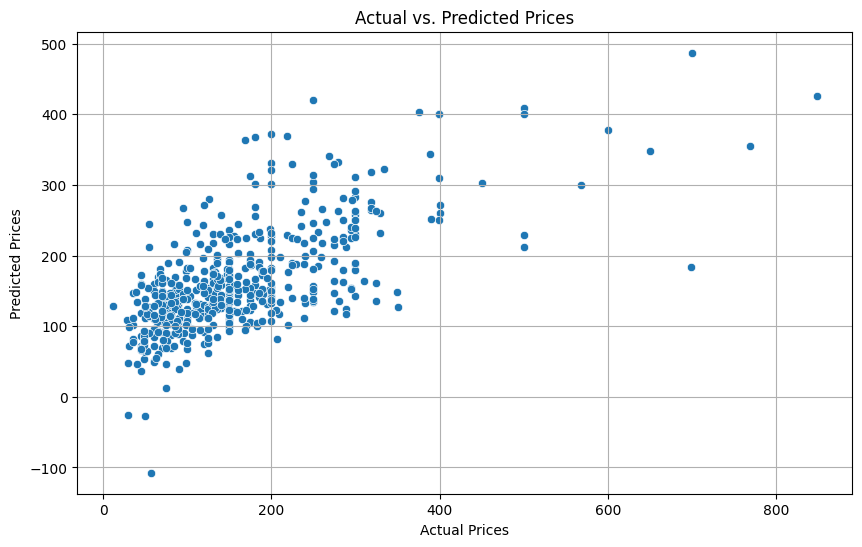

In [139]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a scatter plot of actual vs. predicted prices
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test, y=y_pred)
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs. Predicted Prices")
plt.grid(True)
plt.show()

In [140]:
from sklearn.linear_model import LinearRegression

# Initialize the Linear Regression model
model = LinearRegression()

# Train the model on the training data
model.fit(X_train, y_train)

print("Linear Regression model trained.")

Linear Regression model trained.


In [141]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model using Mean Squared Error (MSE) and Root Mean Squared Error (RMSE)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R2): {r2:.2f}")

Mean Squared Error (MSE): 6529.59
Root Mean Squared Error (RMSE): 80.81
R-squared (R2): 0.45


Summary of Findings and Recommendations Based on the topic modeling and sentiment analysis, we can identify key areas that influence guest sentiment:

Topic 0: (Likely Non-English Reviews) This topic has a negative average compound sentiment score, suggesting that there might be issues with non-English reviews or that reviews in other languages tend to be more negative. Further investigation into these reviews might be necessary.

Topic 1: (Positive Experiences - Location/Host/Apartment) This topic has a high positive average compound sentiment score. The top words indicate that guests appreciate the location, the host, and the apartment itself. Hosts should continue to highlight these aspects in their listings and maintain good communication and a clean, comfortable space.

Topic 2: (Booking/Check-in/Communication) This topic has a moderately positive average compound sentiment score. Words related to arrival, reservation, and communication suggest that smooth check-in processes and good communication are important for a positive guest experience. Hosts should ensure clear instructions for check-in and be responsive to guest inquiries.

Topic 3: (Location/Walking Distance/Nearby Attractions) This topic also has a high positive average compound sentiment score, with top words emphasizing location, walkability, and proximity to restaurants and attractions. This reinforces the importance of location and suggests that highlighting nearby points of interest can attract guests and lead to positive reviews.

Topic 4: (Room/House/Cleanliness/Comfort) This topic has a high positive average compound sentiment score, focusing on the physical space itself - the room, house, cleanliness, and comfort. Maintaining a clean and comfortable environment is crucial for guest satisfaction.

Actionable Insights for Hosts:

Emphasize Location and Nearby Attractions: Guests highly value good locations and easy access to attractions, as seen in Topics 1 and 3. Hosts should prominently feature their property's location advantages and list nearby restaurants, shops, and points of interest in their listing descriptions. Prioritize Cleanliness and Comfort: Topic 4 highlights the importance of a clean and comfortable space for positive reviews. Hosts should ensure their properties are meticulously cleaned and well-maintained. Ensure Smooth Communication and Check-in: Topic 2 suggests that good communication and a seamless check-in process contribute to positive sentiment. Hosts should provide clear and timely communication, detailed check-in instructions, and be available to answer guest questions. Maintain Positive Host-Guest Interactions: Topic 1 indicates that positive interactions with the host are highly valued. Hosts should be welcoming, helpful, and responsive to guest needs. Investigate Non-English Reviews: The negative sentiment associated with Topic 0 warrants further investigation into non-English reviews to understand the specific issues raised by those guests. By focusing on these areas, Airbnb hosts in Boston can improve guest satisfaction, attract more bookings, and potentially increase their profitability.